# Segment a whole slide

Segment nuclei across the TCGA-AC-A6IW breast slide using the PanopTILs model from
[training](training.ipynb). This patient is in the tutorial’s validation split.

Select tissue tiles, save nucleus polygons, merge fragments at tile boundaries,
and inspect the results at slide and nucleus scale. The output contains nuclei
and cell types, not tissue-region segmentation.

The [slide](https://portal.gdc.cancer.gov/files/24c1a3c2-cef7-48a3-9d76-3ded34894107)
is an open-access TCGA image hosted by the NCI Genomic Data Commons (GDC).
Please acknowledge TCGA and GDC when using it. The download is about 123 MB.

## Setup

This example uses OpenSlide. Install its Python package and bundled library with
`python -m pip install openslide-python openslide-bin`.

In [1]:
import json
from pathlib import Path

import albumentations as A
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import openslide
import polars as pl
import requests
import torch
from matplotlib.patches import Patch
from safetensors import safe_open
from shapely.geometry import box

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.inference.wsi_segmenter import WsiSegmenter
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.albu_transforms import MinMaxNormalization
from cellseg_models_pytorch.wsi import SlideReader

torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
slide_path = Path("../../data/wsi/TCGA-AC-A6IW.svs")
checkpoint_path = Path("training-checkpoints/epoch_05/model.safetensors")
output_dir = Path("wsi-results")
tile_size = 1024
print(f"Device: {device}")


Device: cuda


## Download the slide

Reuse the downloaded slide on later runs. A temporary file keeps an interrupted
download separate from the complete slide.

In [2]:
slide_path.parent.mkdir(parents=True, exist_ok=True)
slide_url = "https://api.gdc.cancer.gov/data/24c1a3c2-cef7-48a3-9d76-3ded34894107"

if not slide_path.exists():
    download_path = slide_path.with_suffix(".part")
    with requests.get(slide_url, stream=True, timeout=120) as response:
        response.raise_for_status()
        with download_path.open("xb") as destination:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                destination.write(chunk)
    download_path.rename(slide_path)


## Read the slide

Level 0 is approximately 0.252 µm/pixel, close to the training images’ 0.25 µm/pixel.
Keep this native resolution for prediction. Read a smaller pyramid level for the
tissue mask and overview.

In [3]:
reader = SlideReader(slide_path, backend="OPENSLIDE")
slide_height, slide_width = reader.dimensions
thumbnail_level = reader.level_from_max_dimension(2048)
thumbnail = reader.read_level(thumbnail_level)

with openslide.OpenSlide(slide_path) as slide:
    pixel_size = float(slide.properties[openslide.PROPERTY_NAME_MPP_X])

print(f"Slide: {slide_width:,} × {slide_height:,} pixels")
print(f"Resolution: {pixel_size:.3f} µm/pixel")


Slide: 28,777 × 34,620 pixels
Resolution: 0.252 µm/pixel


## Select tissue tiles

Inspect the mask before segmentation, especially around pale or fatty tissue.
Keep all selected tiles so separate tissue fragments are included. The tile grid
uses level-zero pixel coordinates.

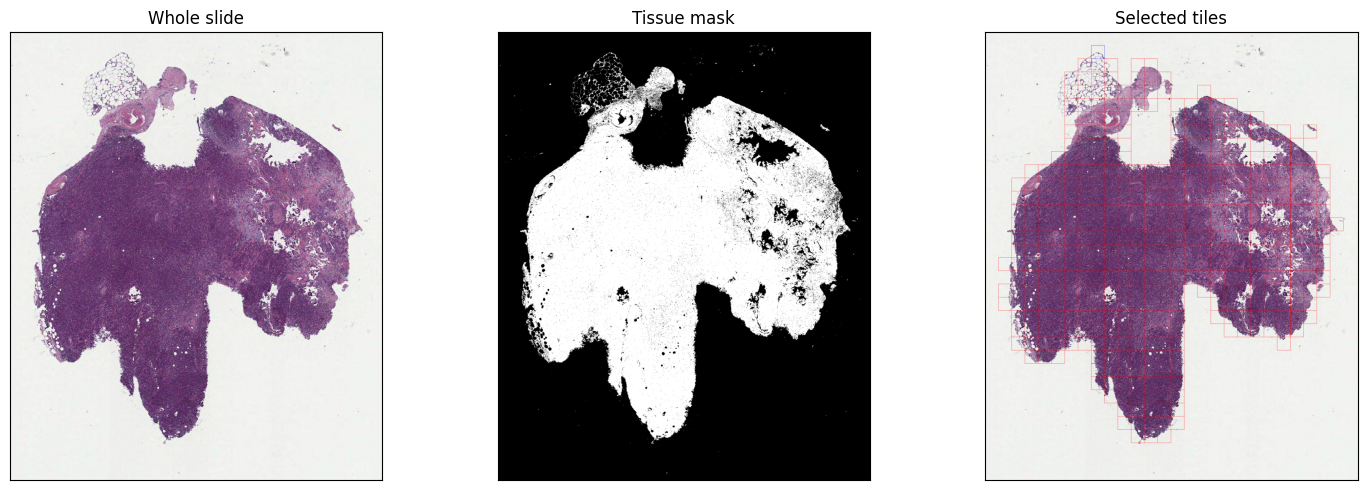

Selected tiles: 453


In [4]:
_, tissue_mask = reader.get_tissue_mask(level=thumbnail_level)
coordinates = reader.get_tile_coordinates(
    width=tile_size,
    tissue_mask=tissue_mask,
    max_background=0.95,
    overlap=0,
)

# Draw the selected full-resolution tiles on the small thumbnail.
annotated = reader.get_annotated_thumbnail(thumbnail, coordinates, linewidth=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(thumbnail)
axes[0].set_title("Whole slide")

axes[1].imshow(tissue_mask, cmap="gray")
axes[1].set_title("Tissue mask")

axes[2].imshow(annotated)
axes[2].set_title("Selected tiles")
for axis in axes:
    axis.set(xticks=[], yticks=[])
fig.tight_layout()
plt.show()

print(f"Selected tiles: {len(coordinates)}")


## Load the model

Use the saved PanopTILs weights and the same min-max normalization as training.

In [5]:
with safe_open(checkpoint_path, framework="pt", device="cpu") as weights:
    class_names = json.loads(weights.metadata()["class_names"])

model = CellPose.from_pretrained(checkpoint_path, device=device)
model.set_inference_mode(mixed_precision=False)
model.post_processor = PostProcessor("cellpose", {"use_gpu": device.type == "cuda"})
normalization = A.Compose([MinMaxNormalization(copy=True)])


## Segment the tissue

Choose a new `output_dir` for each run. Each batch is processed and saved as
tile-level GeoParquet, so the full-resolution slide is never loaded into memory.

In [6]:
output_dir.mkdir(exist_ok=False)
segmenter = WsiSegmenter(
    reader=reader,
    model=model,
    level=0,
    coordinates=coordinates.coordinates,
    batch_size=4,
    normalization=normalization,
)
segmenter.segment(output_dir / "tiles")


100%|██████████| 114/114 [04:27<00:00,  2.35s/batch]


## Merge tile boundaries

Join nucleus fragments across neighboring tiles and assign slide-wide IDs. The
merge reads the saved polygons, not the full-resolution image. These coordinates
are pixels, not geographic coordinates. Fragments within two pixels of a shared
edge can join; inspect crowded boundaries for incorrect joins.


In [7]:
merged_path = output_dir / "nuclei.parquet"
segmenter.merge_instances(
    src=output_dir / "tiles",
    dst=merged_path,
    simplify_level=0.1,
)
nuclei = gpd.read_parquet(merged_path)

# Class 0 inside a predicted nucleus is distinct from empty background.
class_labels = ["untyped (class 0)", *class_names[1:]]
counts = pl.DataFrame(
    {
        "Cell type": class_labels,
        "Nuclei": np.bincount(
            nuclei["class_name"].to_numpy(), minlength=len(class_labels)
        ),
    }
)
print(f"Merged nuclei: {len(nuclei):,}")
counts


Merged nuclei: 174,013


Cell type,Nuclei
str,i64
"""untyped (class 0)""",0
"""neoplastic""",132252
"""stromal""",21961
"""inflammatory""",15148
"""epithelial""",0
"""other""",0
"""unknown""",4652


## Inspect the whole-slide result

Use the same colours in the slide overview and detailed overlays. Cell-type
predictions are model outputs; this slide does not have complete nucleus labels
for a whole-slide accuracy score. The large blue region near the lower tissue
edge is a false positive: inspect tissue edges as well as dense cell regions.


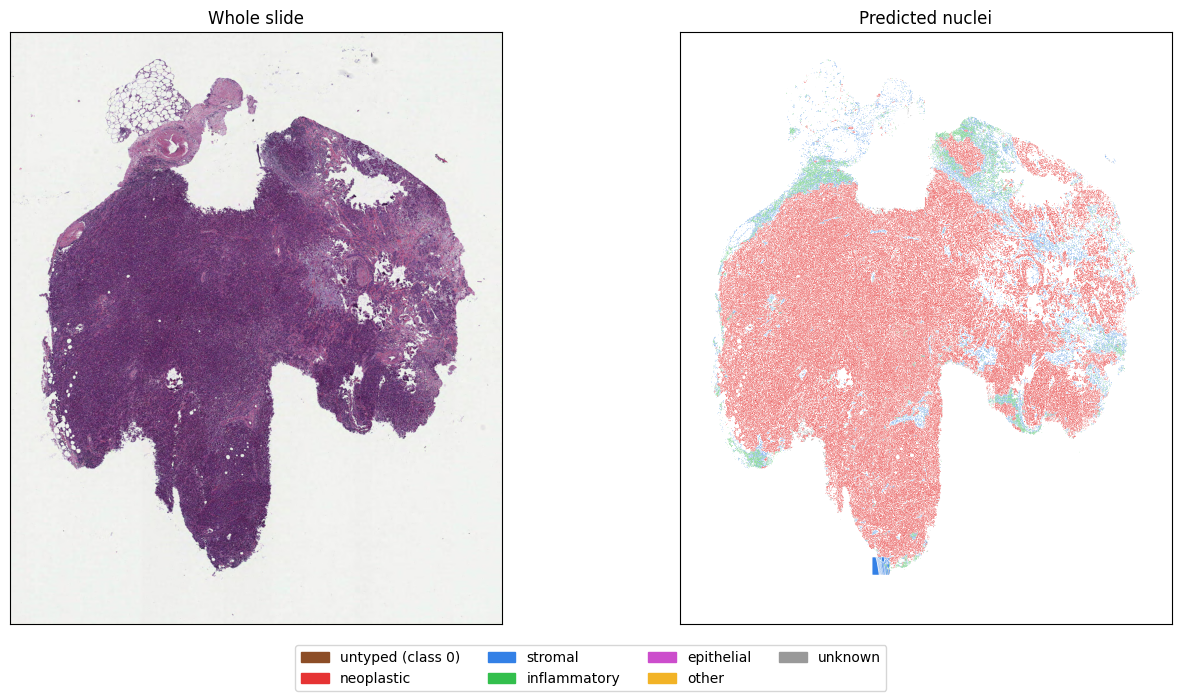

In [8]:
class_palette = np.array(
    [
        [0.55, 0.3, 0.15],
        [0.9, 0.2, 0.2],
        [0.2, 0.5, 0.9],
        [0.2, 0.75, 0.3],
        [0.8, 0.3, 0.8],
        [0.95, 0.7, 0.15],
        [0.6, 0.6, 0.6],
    ]
)
colours = class_palette[nuclei["class_name"].to_numpy()]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(thumbnail, extent=(0, slide_width, slide_height, 0))
axes[0].set_title("Whole slide")

nuclei.plot(ax=axes[1], color=colours, linewidth=0)
axes[1].set_title("Predicted nuclei")
for axis in axes:
    # Image coordinates increase downward on the slide.
    axis.set(xlim=(0, slide_width), ylim=(slide_height, 0), xticks=[], yticks=[])
fig.legend(
    [Patch(color=colour) for colour in class_palette],
    class_labels,
    loc="lower center",
    ncol=4,
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


## Inspect nuclei and tile seams

Compare the predicted boundaries with the image. The dashed line marks a tile
boundary; nuclei crossing it should remain single objects in the merged output.

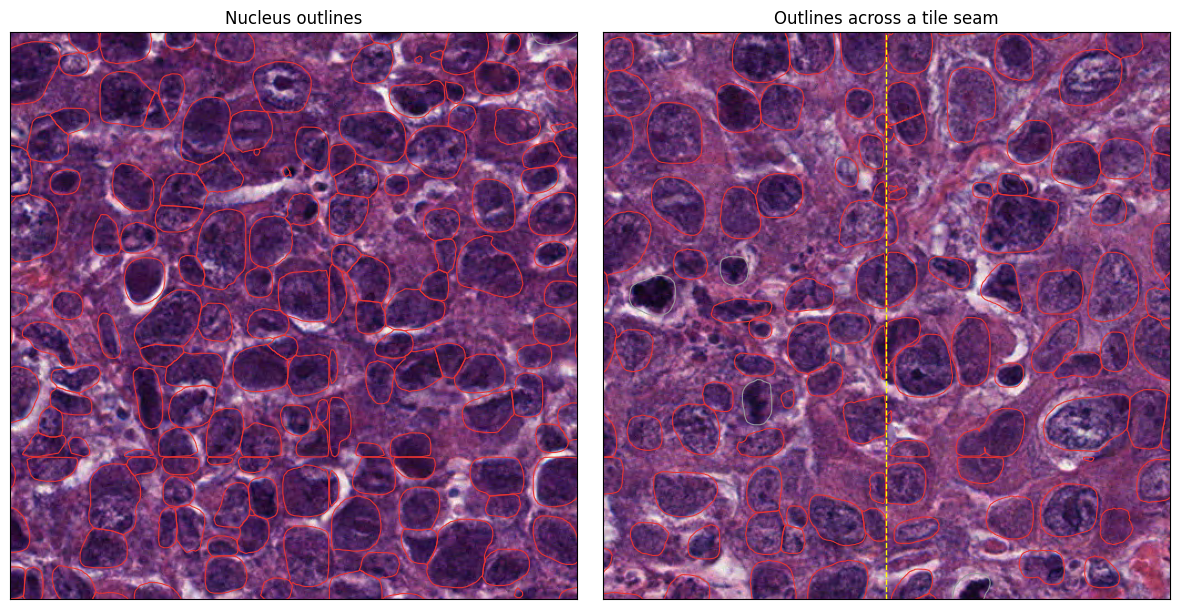

In [9]:
def plot_region(axis, bounds, title):
    x, y, width, height = bounds
    image = reader.read_region(bounds, level=0)
    axis.imshow(image, extent=(x, x + width, y + height, y))

    # Query only the polygons visible in this crop.
    indices = nuclei.sindex.query(
        box(x, y, x + width, y + height), predicate="intersects"
    )
    visible = nuclei.iloc[indices]
    visible.boundary.plot(
        ax=axis, color=class_palette[visible["class_name"].to_numpy()], linewidth=0.8
    )
    axis.set(
        xlim=(x, x + width), ylim=(y + height, y), xticks=[], yticks=[], title=title
    )


regions = [(12000, 16000, 512, 512), (16128, 16000, 512, 512)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_region(axes[0], regions[0], "Nucleus outlines")
plot_region(axes[1], regions[1], "Outlines across a tile seam")
axes[1].axvline(16384, color="yellow", linestyle="--", linewidth=1)
fig.tight_layout()
plt.show()


The merged result is saved in `wsi-results/nuclei.parquet`. Keep the tile files
while inspecting the merge; they preserve the predictions before stitching.